In [3]:
import pandas as pd
import math

data = pd.DataFrame({
    "Outlook": ["Sunny","Sunny","Overcast","Rain","Rain","Rain","Overcast",
                "Sunny","Sunny","Rain","Sunny","Overcast","Overcast","Rain"],
    "Temperature": ["Hot","Hot","Hot","Mild","Cool","Cool","Cool",
                    "Mild","Cool","Mild","Mild","Mild","Hot","Mild"],
    "Humidity": ["High","High","High","High","Normal","Normal","Normal",
                 "High","Normal","Normal","Normal","High","Normal","High"],

    "Windy": ["False","True","False","False","False","True","True",
              "False","False","False","True","True","False","True"],

    "Play": ["No","No","Yes","Yes","Yes","No","Yes",
             "No","Yes","Yes","Yes","Yes","Yes","No"]
})

print(data)

     Outlook Temperature Humidity  Windy Play
0      Sunny         Hot     High  False   No
1      Sunny         Hot     High   True   No
2   Overcast         Hot     High  False  Yes
3       Rain        Mild     High  False  Yes
4       Rain        Cool   Normal  False  Yes
5       Rain        Cool   Normal   True   No
6   Overcast        Cool   Normal   True  Yes
7      Sunny        Mild     High  False   No
8      Sunny        Cool   Normal  False  Yes
9       Rain        Mild   Normal  False  Yes
10     Sunny        Mild   Normal   True  Yes
11  Overcast        Mild     High   True  Yes
12  Overcast         Hot   Normal  False  Yes
13      Rain        Mild     High   True   No


In [4]:
# Entropy
def entropy(x):
    p = x.value_counts(normalize=True)
    e = 0
    for i in p:
        e = e - i * math.log2(i)
    return e
# Information Gain
def gain(column):
    total = entropy(data["Play"])
    result = 0
    for value in data[column].unique():
        part = data[data[column] == value]
        result = result + (len(part) / len(data)) * entropy(part["Play"])
    return total - result

# Find best attribute
attributes = ["Outlook", "Temperature", "Humidity", "Windy"]

for a in attributes:
    print(a, "=", round(gain(a), 4))

best = max(attributes, key=gain)

print("Best Splitting Attribute:", best)

Outlook = 0.2467
Temperature = 0.0292
Humidity = 0.1518
Windy = 0.0481
Best Splitting Attribute: Outlook


In [5]:
import pandas as pd
import math

data = pd.DataFrame({
    "Outlook": ["Sunny","Sunny","Overcast","Rain","Rain","Rain","Overcast",
                "Sunny","Sunny","Rain","Sunny","Overcast","Overcast","Rain"],
    "Temperature": ["Hot","Hot","Hot","Mild","Cool","Cool","Cool",
                    "Mild","Cool","Mild","Mild","Mild","Hot","Mild"],
    "Humidity": ["High","High","High","High","Normal","Normal","Normal",
                 "High","Normal","Normal","Normal","High","Normal","High"],
    "Windy": ["False","True","False","False","False","True","True",
              "False","False","False","True","True","False","True"],
    "Play": ["No","No","Yes","Yes","Yes","No","Yes",
             "No","Yes","Yes","Yes","Yes","Yes","No"]
})


# Entropy
def entropy(x):
    p = x.value_counts(normalize=True)

    e = 0

    for i in p:
        e = e - i * math.log2(i)

    return e


# Information Gain
def gain(data, column):
    total = entropy(data["Play"])

    result = 0

    for value in data[column].unique():

        part = data[data[column] == value]

        result = result + (len(part) / len(data)) * entropy(part["Play"])

    return total - result


# Build Decision Tree
def build_tree(data, attributes):

    # If all examples belong to one class
    if len(data["Play"].unique()) == 1:
        return data["Play"].iloc[0]

    # If no attributes are left
    if len(attributes) == 0:
        return data["Play"].mode()[0]

    # Find best attribute
    best = max(attributes, key=lambda x: gain(data, x))

    tree = {best: {}}

    # Create branches
    for value in data[best].unique():

        subset = data[data[best] == value]

        remaining_attributes = [
            a for a in attributes if a != best
        ]

        tree[best][value] = build_tree(
            subset,
            remaining_attributes
        )

    return tree


attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Windy"
]

tree = build_tree(data, attributes)

print(tree)

{'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Windy': {'False': 'Yes', 'True': 'No'}}}}


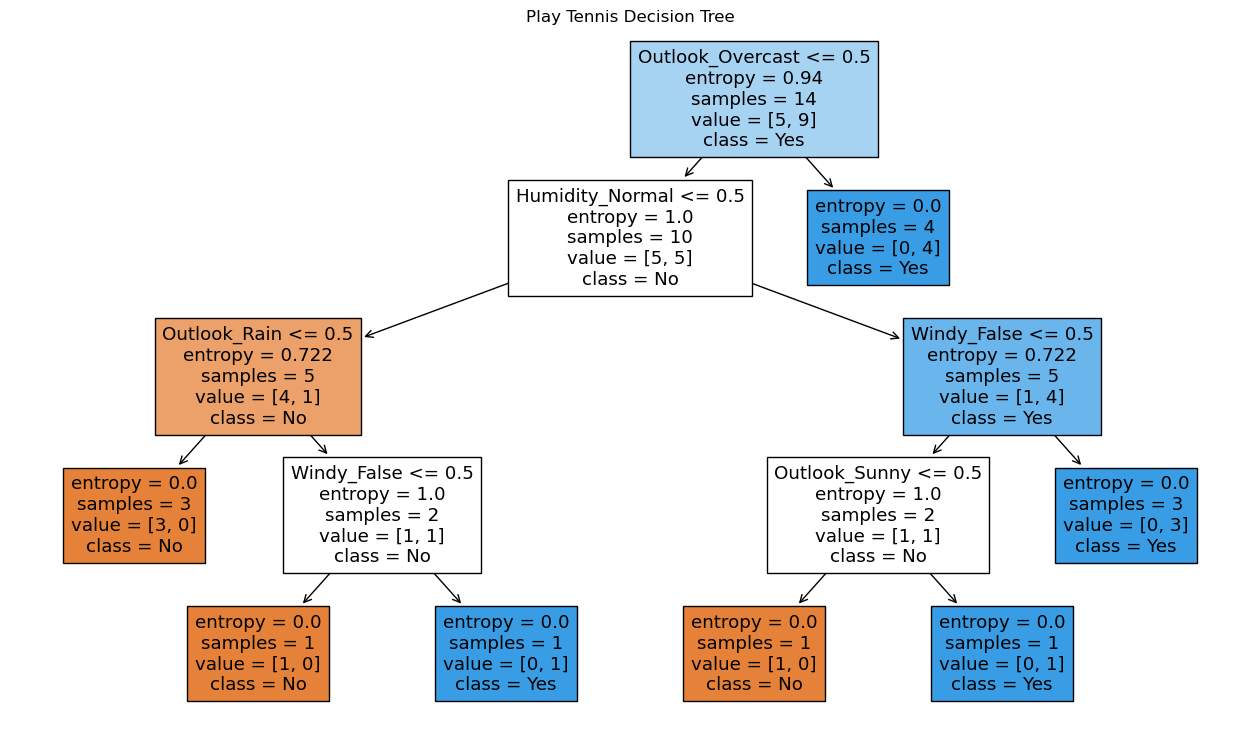

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
import pandas as pd

# Convert categorical values to numbers
X = pd.get_dummies(data[["Outlook", "Temperature", "Humidity", "Windy"]])
y = data["Play"].map({"No": 0, "Yes": 1})

# Create Decision Tree
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X, y)

# Plot
plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No", "Yes"],
    filled=True
)

plt.title("Play Tennis Decision Tree")
plt.show()